# SecondLook | 02 Data Cleaning and Feature Engineering (SQL + Pandas)

**Goal:** turn the raw Kaggle data into **one clean, model-ready table with one row per applicant.**

The EDA (`01_eda.ipynb`) told us *what* needs fixing and *which* signals matter. This notebook acts on those findings:

```
application_train.csv ──► clean (Pandas) ──► engineer ratios ──┐
                                                                ├──► LEFT JOIN ──► features.parquet
6 history tables ──► SQLite ──► SQL GROUP BY per applicant ────┘
```

| Section | What we do | Bootcamp topic |
|---|---|---|
| 2 | Clean the main table using the EDA decisions | Data cleaning, type correction, missing data |
| 3 | Engineer ratio and summary features | Feature engineering with Pandas/NumPy |
| 4 | Load 58 million history rows into a SQLite database | Relational databases, CREATE/INSERT, indexes |
| 5 | Summarise each history table per applicant with SQL | SELECT, JOIN, GROUP BY, CTEs, aggregate functions |
| 6 | Join everything into one table | Merging and joining datasets (SQL results into Pandas) |
| 7 | Validate the result | Data quality checks |
| 8 | Check which features carry signal | Preparing for machine learning |
| 9 | Save the table and a feature dictionary | File handling, documentation |

All the logic lives in reusable modules in `src/secondlook/` (`cleaning.py`, `sql_features.py`, `features.py`) so the model training and the Streamlit app use **exactly the same transformations**. This notebook calls those functions step by step and explains each one.

## 1. Setup

In [1]:
import sys
import sqlite3
import inspect
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "secondlook").exists())
sys.path.insert(0, str(ROOT / "src"))

from secondlook.config import DB_PATH, FIGURES_DIR, ID_COL, TARGET_COL
from secondlook.data import load_table, shrink
from secondlook.cleaning import clean_application, add_application_features
from secondlook.sql_features import QUERIES, build_database, run_query, attach_history
from secondlook.features import FEATURES_PATH, META_PATH, PROTECTED_COLS

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

## 2. Clean the main application table

Every cleaning step below comes from a specific EDA finding:

| Step | EDA finding | Action |
|---|---|---|
| 1 | `DAYS_EMPLOYED = 365243` (1,000 years) in 18% of rows, almost all pensioners | Set to missing, keep a flag `DAYS_EMPLOYED_ANOM` |
| 2 | `CODE_GENDER = "XNA"` in 4 rows | Set to missing |
| 3 | One income of 117,000,000 (about 800× the median) | Cap income at the 99.9th percentile |
| 4 | `DAYS_*` columns are negative day counts | Convert to positive **years** |
| 5 | `OCCUPATION_TYPE` 31% missing | Fill with `"Unknown"` (no occupation recorded is information) |
| 6 | Building columns come in 3 near-identical versions (`_AVG`, `_MODE`, `_MEDI`) | Keep `_AVG` only |

Here is the function that does it (from `src/secondlook/cleaning.py`):

In [2]:
print(inspect.getsource(clean_application))

def clean_application(df: pd.DataFrame, income_cap: float | None = None) -> pd.DataFrame:
    """Return a cleaned copy of application_train (or application_test).

    Steps (each one traced back to an EDA finding):
      1. DAYS_EMPLOYED = 365243 is a placeholder for "not employed" (18% of rows, mostly
         pensioners) -> set to NaN and keep the information in a flag column.
      2. CODE_GENDER "XNA" (4 rows) -> NaN.
      3. Cap AMT_INCOME_TOTAL at the 99.9th percentile to neutralise the 117M data-entry error.
      4. Convert negative day counts to positive years (easier to read and explain).
      5. Missing OCCUPATION_TYPE -> "Unknown" (31% missing; "no occupation recorded" is information).
      6. Drop the duplicate _MODE / _MEDI building columns.

    Pass income_cap from the training data when cleaning new applicants, so the
    same cap is used everywhere.
    """
    df = df.copy()

    # 1. Employment placeholder
    anomaly = df["DAYS_EMPLOYED"].eq(DAYS_EMPLOYED_PLACE

In [3]:
raw = load_table("application_train")
app = clean_application(raw)
income_cap = app.attrs["income_cap"]

checks = pd.DataFrame({
    "before": [raw.shape[1], (raw["DAYS_EMPLOYED"] == 365243).sum(), (raw["CODE_GENDER"] == "XNA").sum(),
               raw["AMT_INCOME_TOTAL"].max(), raw["OCCUPATION_TYPE"].isna().sum()],
    "after": [app.shape[1], app["DAYS_EMPLOYED_ANOM"].sum(), app["CODE_GENDER"].isna().sum(),
              app["AMT_INCOME_TOTAL"].max(), (app["OCCUPATION_TYPE"] == "Unknown").sum()],
}, index=["columns", "employment placeholder rows (flagged after)", "gender XNA (missing after)",
          "max income", "occupation missing ('Unknown' after)"])
print(f"Income cap (99.9th percentile): {income_cap:,.0f}  ->  {(raw['AMT_INCOME_TOTAL'] > income_cap).sum()} applicants capped")
checks.style.format("{:,.0f}")

Income cap (99.9th percentile): 900,000  ->  278 applicants capped


,before,after
columns,122,95
employment placeholder rows (flagged after),"55,374","55,374"
gender XNA (missing after),4,4
max income,"117,000,000","900,000"
occupation missing ('Unknown' after),"96,391","96,391"


**Interpretation:**
- The table went from **122 to 95 columns**: we dropped the duplicate `_MODE` / `_MEDI` building columns and replaced five `DAYS_*` columns with readable `*_YEARS` versions.
- The income cap is **900,000**, and it affects only **278 applicants (0.09%)**. The 117 million error is gone, while genuine high earners keep realistic values.
- The **55,374 employment placeholders** are now missing values *plus* a flag, so the model still knows these applicants are mostly pensioners (a lower-risk group in EDA).
- **96,391 applicants** now have occupation `"Unknown"` instead of a blank.
- We store the income cap so that **new applicants in the app are cleaned with the same cap**. If we re-computed it on each new applicant, the rule would change from person to person.

## 3. Engineer application features

Raw columns don't always express what a loan officer actually thinks about. These new features encode lending logic:

| Feature | Formula | Why |
|---|---|---|
| `CREDIT_TO_INCOME` | loan ÷ income | How big the loan is for this person |
| `ANNUITY_TO_INCOME` | regular payment ÷ income | Repayment burden |
| `CREDIT_TO_GOODS` | loan ÷ item price | Above 1 = borrowing extra cash on top of the purchase (11.5% default in EDA) |
| `CREDIT_TERM` | loan ÷ annuity | Roughly the number of payments: a longer term means smaller payments |
| `INCOME_PER_PERSON` | income ÷ family members | Income that is actually available per person |
| `EXT_SOURCE_MEAN/MIN/MAX/STD` | across the 3 external scores | The average score was the strongest signal in EDA (18.7% vs 2.5% default) |
| `EXT_SOURCE_N_MISSING`, `*_MISSING` flags | count of missing scores | Fewer scores = thinner file |
| `EMPLOYED_TO_AGE` | years employed ÷ age | Job stability relative to age |
| `N_DOCUMENTS`, `N_CONTACTS` | sums of 0/1 flags | How complete the application is |
| `BUREAU_ENQUIRIES_YEAR` | sum of credit enquiries | Many recent enquiries = actively seeking credit |

`CREDIT_TO_INCOME`, `ANNUITY_TO_INCOME`, `CREDIT_TO_GOODS` and `CREDIT_TERM` matter for the app too: they are the **levers** SecondLook will adjust when it suggests a realistic path to approval (e.g. "a smaller loan" or "a longer term").

In [4]:
app = add_application_features(app)
new_cols = ["CREDIT_TO_INCOME", "ANNUITY_TO_INCOME", "CREDIT_TO_GOODS", "CREDIT_TERM", "INCOME_PER_PERSON",
            "EXT_SOURCE_MEAN", "EXT_SOURCE_STD", "EXT_SOURCE_N_MISSING", "EMPLOYED_TO_AGE",
            "N_DOCUMENTS", "N_CONTACTS", "BUREAU_ENQUIRIES_YEAR"]
print(f"Columns after feature engineering: {app.shape[1]}")
app[new_cols].describe(percentiles=[0.5]).T[["count", "mean", "50%", "min", "max"]]

Columns after feature engineering: 112


,count,mean,50%,min,max
CREDIT_TO_INCOME,"307,511.000",3.958,3.265,0.083,84.737
ANNUITY_TO_INCOME,"307,499.000",0.181,0.163,0.007,1.876
CREDIT_TO_GOODS,"307,233.000",1.123,1.119,0.150,6.000
CREDIT_TERM,"307,499.000",21.612,20.000,8.037,45.305
INCOME_PER_PERSON,"307,509.000","92,654.648","75,000.000","2,812.500","900,000.000"
EXT_SOURCE_MEAN,"307,339.000",0.509,0.525,0.000,0.879
EXT_SOURCE_STD,"270,602.000",0.151,0.136,0.000,0.652
EXT_SOURCE_N_MISSING,"307,511.000",0.764,1.000,0.000,3.000
EMPLOYED_TO_AGE,"252,137.000",0.157,0.119,0.000,0.729
N_DOCUMENTS,"307,511.000",0.930,1.000,0.000,4.000


**Interpretation:**
- A typical applicant borrows about **3.3× their annual income** (median `CREDIT_TO_INCOME`), and the median `CREDIT_TERM` is about **20 payments**.
- The median `CREDIT_TO_GOODS` is about **1.12**: most loans are slightly larger than the item price, which usually covers insurance or fees.
- `EXT_SOURCE_MEAN` is available for almost every applicant even though `EXT_SOURCE_1` alone is 56% missing, because it averages whichever scores exist. That's why combining the three scores is more useful than any single one.
- Division by zero (e.g. a missing annuity) produces infinity, which the function converts to missing so it can't break the model.

## 4. Load the credit-history tables into a SQL database

The six history tables hold **58 million rows** (about 2.5 GB as CSV). Rather than holding them all in memory with Pandas, we put them in a **SQLite database**: a real relational database stored in one file (`data/interim/secondlook.db`) that needs no server.

**Why SQL here?**
- **Memory:** the data is streamed from the zip in chunks of 500,000 rows and appended to the database (an `INSERT`), so we never need all 58 million rows in memory at once.
- **Speed:** we create **indexes** on the join keys (`SK_ID_CURR`, `SK_ID_BUREAU`), the same way a production database would, so `GROUP BY` and `JOIN` run quickly.
- **Clarity:** each summary becomes a readable query that a teammate (or an interviewer) can check line by line.
- **Reuse:** the same database will feed the **AI Analyst agent** in Phase 2, which answers plain-English questions by writing SQL against these tables.

We load only the columns the queries need. The first run takes about 3 minutes; after that, the function sees that the tables already exist and skips loading.

In [5]:
load_summary = build_database()
print(f"Database file: {DB_PATH.relative_to(ROOT)}  ({DB_PATH.stat().st_size / 1e9:.1f} GB)")
load_summary.style.format({"rows": "{:,}"})

Database file: data\interim\secondlook.db  (2.3 GB)


,rows,columns,load_seconds,loaded_now
table,,,,
bureau,"1,716,428",11,0.000000,False
bureau_balance,"27,299,925",3,0.800000,False
previous_application,"1,670,214",9,0.000000,False
installments_payments,"13,605,401",6,0.400000,False
POS_CASH_balance,"10,001,358",5,0.300000,False
credit_card_balance,"3,840,312",9,0.100000,False


**Interpretation:** all six tables are in the database. `bureau_balance` is the largest (**27.3 million** monthly records), followed by `installments_payments` (**13.6 million** payments). Most applicants have dozens of history rows each, which is why we need to **summarise** them before modelling.

We can query the database directly, just like in DBeaver. For example, how many bureau loans are active vs closed:

In [6]:
with sqlite3.connect(DB_PATH) as conn:
    display(pd.read_sql_query('''
        SELECT CREDIT_ACTIVE,
               COUNT(*)                          AS n_loans,
               ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM bureau), 1) AS pct
        FROM bureau
        GROUP BY CREDIT_ACTIVE
        ORDER BY n_loans DESC
    ''', conn))

,CREDIT_ACTIVE,n_loans,pct
0,Closed,1079273,62.900
1,Active,630607,36.700
2,Sold,6527,0.400
3,Bad debt,21,0.000


## 5. Summarise each history table with SQL

A model needs **one row per applicant**, but the history tables have many rows per applicant. Each query below uses `GROUP BY SK_ID_CURR` to turn an applicant's history into a few meaningful numbers.

**A SQLite trick used throughout:** a comparison like `CREDIT_ACTIVE = 'Active'` evaluates to **1 (true) or 0 (false)**. So:
- `SUM(condition)` = **how many** rows meet the condition
- `AVG(condition)` = **what share** of rows meet it

Feature names start with a prefix that shows where they came from: `BUR_` (bureau), `BB_` (bureau balance), `PREV_` (previous applications), `INST_` (installments), `POS_` (point-of-sale/cash loans), `CC_` (credit cards).

### 5.1 Credit bureau: loans at other lenders

In [7]:
print(QUERIES["bureau"])
bureau_feats = run_query("bureau")
print(f"{len(bureau_feats):,} applicants, {bureau_feats.shape[1]} features")
bureau_feats.head()


        -- Loans the applicant has at OTHER lenders (Credit Bureau)
        SELECT
            SK_ID_CURR,
            COUNT(*)                                            AS BUR_N_LOANS,
            SUM(CREDIT_ACTIVE = 'Active')                       AS BUR_N_ACTIVE,
            AVG(CREDIT_ACTIVE = 'Active')                       AS BUR_ACTIVE_SHARE,
            SUM(CREDIT_ACTIVE = 'Bad debt')                     AS BUR_N_BAD_DEBT,
            COUNT(DISTINCT CREDIT_TYPE)                         AS BUR_N_CREDIT_TYPES,
            -MAX(DAYS_CREDIT) / 365.25                          AS BUR_YEARS_SINCE_LAST_LOAN,
            -MIN(DAYS_CREDIT) / 365.25                          AS BUR_YEARS_SINCE_FIRST_LOAN,
            SUM(AMT_CREDIT_SUM)                                 AS BUR_TOTAL_CREDIT,
            SUM(AMT_CREDIT_SUM_DEBT)                            AS BUR_TOTAL_DEBT,
            SUM(AMT_CREDIT_SUM_DEBT) / NULLIF(SUM(AMT_CREDIT_SUM), 0) AS BUR_DEBT_TO_CREDIT,
            SUM(AMT_CREDIT

305,811 applicants, 14 features


,BUR_N_LOANS,BUR_N_ACTIVE,BUR_ACTIVE_SHARE,BUR_N_BAD_DEBT,BUR_N_CREDIT_TYPES,BUR_YEARS_SINCE_LAST_LOAN,BUR_YEARS_SINCE_FIRST_LOAN,BUR_TOTAL_CREDIT,BUR_TOTAL_DEBT,BUR_DEBT_TO_CREDIT,BUR_TOTAL_OVERDUE,BUR_MAX_DAYS_OVERDUE,BUR_N_OVERDUE_NOW,BUR_N_PROLONGED
SK_ID_CURR,,,,,,,,,,,,,,
100001,7,3,0.429,0,1,0.134,4.304,"1,453,365.000","596,686.500",0.411,0.000,0,0,0
100002,8,2,0.250,0,2,0.282,3.934,"865,055.565","245,781.000",0.284,0.000,0,0,0
100003,4,1,0.250,0,2,1.659,7.080,"1,017,400.500",0.000,0.000,0.000,0,0,0
100004,2,0,0.000,0,1,1.117,3.630,"189,037.800",0.000,0.000,0.000,0,0,0
100005,3,2,0.667,0,2,0.170,1.021,"657,126.000","568,408.500",0.865,0.000,0,0,0


**Interpretation:** each applicant now has one row describing their outside credit: how many loans, how many still active, total debt vs total credit (`BUR_DEBT_TO_CREDIT`, a debt-utilisation measure), how recently they last borrowed, and any overdue amounts.

The query returns **305,811 applicants**, more than our 307,511 × 85.7% because the bureau table also covers Kaggle's test applicants. The LEFT JOIN in Section 6 keeps only our training applicants.

### 5.2 Bureau monthly balance: a CTE and a JOIN

`bureau_balance` doesn't have `SK_ID_CURR`, only `SK_ID_BUREAU`. So we summarise **per bureau loan** first in a **CTE** (`WITH per_loan AS (...)`), then `JOIN` to `bureau` to find which applicant each loan belongs to, and summarise again per applicant.

In [8]:
print(QUERIES["bureau_balance"])
bb_feats = run_query("bureau_balance")
print(f"{len(bb_feats):,} applicants, {bb_feats.shape[1]} features")
bb_feats.describe().T[["count", "mean", "50%", "max"]]


        -- Monthly status of bureau loans. STATUS: 0 = on time, 1-5 = days past due buckets
        -- (1 = 1-30 days ... 5 = 120+ days or written off), C = closed, X = unknown.
        WITH per_loan AS (
            SELECT
                SK_ID_BUREAU,
                COUNT(*)                                        AS n_months,
                SUM(STATUS IN ('1','2','3','4','5'))            AS n_late_months,
                SUM(STATUS IN ('3','4','5'))                    AS n_severe_months
            FROM bureau_balance
            GROUP BY SK_ID_BUREAU
        )
        SELECT
            b.SK_ID_CURR,
            SUM(p.n_months)                                     AS BB_N_MONTHS,
            SUM(p.n_late_months) * 1.0 / SUM(p.n_months)        AS BB_LATE_MONTH_SHARE,
            SUM(p.n_severe_months)                              AS BB_N_SEVERE_LATE_MONTHS
        FROM per_loan p
        JOIN bureau b ON b.SK_ID_BUREAU = p.SK_ID_BUREAU
        GROUP BY b.SK_ID_CURR
    


134,542 applicants, 3 features


,count,mean,50%,max
BB_N_MONTHS,"134,542.000",179.719,125.000,"2,791.000"
BB_LATE_MONTH_SHARE,"134,542.000",0.016,0.000,1.000
BB_N_SEVERE_LATE_MONTHS,"134,542.000",0.470,0.000,346.000


**Interpretation:** monthly bureau records exist for only about **134,500 applicants**, fewer than half of those with bureau loans, so these features will be missing for most people (the model handles that). Where present, the average share of months spent late (`BB_LATE_MONTH_SHARE`) is low, **under 2%**, so a high value really stands out.

### 5.3 Previous applications at Home Credit

In [9]:
print(QUERIES["previous_application"])
prev_feats = run_query("previous_application")
print(f"{len(prev_feats):,} applicants, {prev_feats.shape[1]} features")
prev_feats.describe().T[["count", "mean", "50%", "max"]]


        -- Earlier applications at Home Credit
        SELECT
            SK_ID_CURR,
            COUNT(*)                                            AS PREV_N_APPS,
            SUM(NAME_CONTRACT_STATUS = 'Approved')              AS PREV_N_APPROVED,
            SUM(NAME_CONTRACT_STATUS = 'Refused')               AS PREV_N_REFUSED,
            AVG(NAME_CONTRACT_STATUS = 'Refused')               AS PREV_REFUSED_SHARE,
            AVG(NAME_CONTRACT_STATUS = 'Canceled')              AS PREV_CANCELED_SHARE,
            AVG(AMT_APPLICATION)                                AS PREV_AVG_AMT_APPLIED,
            AVG(AMT_CREDIT / NULLIF(AMT_APPLICATION, 0))        AS PREV_AVG_GRANTED_TO_APPLIED,
            AVG(CNT_PAYMENT)                                    AS PREV_AVG_TERM,
            -MAX(DAYS_DECISION) / 365.25                        AS PREV_YEARS_SINCE_LAST_DECISION,
            SUM(NAME_CONTRACT_STATUS = 'Refused' AND DAYS_DECISION >= -365) AS PREV_N_REFUSED_LAST_YEAR
        FROM previous

338,857 applicants, 10 features


,count,mean,50%,max
PREV_N_APPS,"338,857.000",4.929,4.000,77.000
PREV_N_APPROVED,"338,857.000",3.060,3.000,27.000
PREV_N_REFUSED,"338,857.000",0.858,0.000,68.000
PREV_REFUSED_SHARE,"338,857.000",0.111,0.000,1.000
PREV_CANCELED_SHARE,"338,857.000",0.129,0.000,1.000
PREV_AVG_AMT_APPLIED,"338,857.000","154,468.279","106,834.500","4,050,000.000"
PREV_AVG_GRANTED_TO_APPLIED,"337,752.000",1.018,1.022,10.180
PREV_AVG_TERM,"338,379.000",14.533,12.000,72.000
PREV_YEARS_SINCE_LAST_DECISION,"338,857.000",1.318,0.832,8.000
PREV_N_REFUSED_LAST_YEAR,"338,857.000",0.339,0.000,54.000


**Interpretation:** for each applicant we now know how often they applied before, how often they were **refused**, whether they were refused **in the last year**, and whether they usually got **more or less than they asked for** (`PREV_AVG_GRANTED_TO_APPLIED`). EDA showed that applicants refused in more than half of their past applications default at **15.9%**, about double the average.

### 5.4 Installment payments: on time, late or short?

This is the most direct measure of **repayment behaviour**. For every past installment, we compare the payment date with the due date and the amount paid with the amount due. A missing payment date means the installment was **never paid**, so we use `COALESCE(..., 1)` to count it as late instead of letting SQL ignore it.

In [10]:
print(QUERIES["installments_payments"])
inst_feats = run_query("installments_payments")
print(f"{len(inst_feats):,} applicants, {inst_feats.shape[1]} features")
inst_feats.describe().T[["count", "mean", "50%", "max"]]


        -- Every installment due on previous Home Credit loans, and how it was paid.
        -- A missing payment date or amount means the installment was never paid,
        -- so COALESCE counts it as late / underpaid instead of ignoring it.
        SELECT
            SK_ID_CURR,
            COUNT(*)                                            AS INST_N_PAYMENTS,
            AVG(COALESCE(DAYS_ENTRY_PAYMENT > DAYS_INSTALMENT, 1)) AS INST_LATE_SHARE,
            AVG(MAX(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT, 0))   AS INST_AVG_DAYS_LATE,
            MAX(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT)           AS INST_MAX_DAYS_LATE,
            AVG(COALESCE(AMT_PAYMENT, 0) < AMT_INSTALMENT)      AS INST_UNDERPAID_SHARE,
            SUM(MAX(AMT_INSTALMENT - COALESCE(AMT_PAYMENT, 0), 0)) AS INST_TOTAL_UNDERPAID,
            AVG(CASE WHEN DAYS_INSTALMENT >= -365
                     THEN COALESCE(DAYS_ENTRY_PAYMENT > DAYS_INSTALMENT, 1) END) AS INST_LATE_SHARE_LAST_YEAR
        FROM installments_paym

339,587 applicants, 7 features


,count,mean,50%,max
INST_N_PAYMENTS,"339,587.000",40.065,25.000,372.000
INST_LATE_SHARE,"339,587.000",0.075,0.018,1.000
INST_AVG_DAYS_LATE,"339,578.000",1.028,0.036,"1,885.386"
INST_MAX_DAYS_LATE,"339,578.000",15.695,1.000,"2,884.000"
INST_UNDERPAID_SHARE,"339,587.000",0.083,0.000,1.000
INST_TOTAL_UNDERPAID,"339,587.000","29,020.930",0.000,"3,037,735.575"
INST_LATE_SHARE_LAST_YEAR,"252,761.000",0.053,0.000,1.000


**Interpretation:** the average applicant paid about **7.5%** of their past installments late, and the median applicant about **2%**. We also measure **how late** (`INST_AVG_DAYS_LATE`, `INST_MAX_DAYS_LATE`), **underpayment** (`INST_UNDERPAID_SHARE`) and **recent** behaviour (`INST_LATE_SHARE_LAST_YEAR`). Recent behaviour usually predicts better than old behaviour: someone who was late years ago but pays on time now is a different risk from someone late last month.

### 5.5 Point-of-sale and cash loans (monthly)

In [11]:
print(QUERIES["POS_CASH_balance"])
pos_feats = run_query("POS_CASH_balance")
print(f"{len(pos_feats):,} applicants, {pos_feats.shape[1]} features")
pos_feats.describe().T[["count", "mean", "50%", "max"]]


        -- Monthly snapshots of previous point-of-sale and cash loans
        SELECT
            SK_ID_CURR,
            COUNT(DISTINCT SK_ID_PREV)                          AS POS_N_LOANS,
            COUNT(*)                                            AS POS_N_MONTHS,
            AVG(SK_DPD > 0)                                     AS POS_LATE_MONTH_SHARE,
            MAX(SK_DPD)                                         AS POS_MAX_DPD,
            COUNT(DISTINCT CASE WHEN NAME_CONTRACT_STATUS = 'Completed' THEN SK_ID_PREV END) AS POS_N_COMPLETED
        FROM POS_CASH_balance
        GROUP BY SK_ID_CURR
    


337,252 applicants, 5 features


,count,mean,50%,max
POS_N_LOANS,"337,252.000",2.776,2.000,26.000
POS_N_MONTHS,"337,252.000",29.655,22.000,295.000
POS_LATE_MONTH_SHARE,"337,252.000",0.021,0.000,1.000
POS_MAX_DPD,"337,252.000",15.294,0.000,"4,231.000"
POS_N_COMPLETED,"337,252.000",2.072,2.000,24.000


**Interpretation:** most applicants have had a few previous point-of-sale or cash loans (median **2**), and most have completed them (median **2** completed). `POS_LATE_MONTH_SHARE` measures how often they were past due. It's rare (about **2%** of months on average), so even a little lateness is informative.

### 5.6 Credit cards (monthly)

In [12]:
print(QUERIES["credit_card_balance"])
cc_feats = run_query("credit_card_balance")
print(f"{len(cc_feats):,} applicants, {cc_feats.shape[1]} features")
cc_feats.describe().T[["count", "mean", "50%", "max"]]


        -- Monthly snapshots of previous Home Credit credit cards
        SELECT
            SK_ID_CURR,
            COUNT(DISTINCT SK_ID_PREV)                          AS CC_N_CARDS,
            COUNT(*)                                            AS CC_N_MONTHS,
            AVG(AMT_BALANCE)                                    AS CC_AVG_BALANCE,
            AVG(AMT_BALANCE / NULLIF(AMT_CREDIT_LIMIT_ACTUAL, 0)) AS CC_AVG_UTILISATION,
            AVG(AMT_DRAWINGS_CURRENT)                           AS CC_AVG_DRAWINGS,
            AVG(AMT_PAYMENT_CURRENT < AMT_INST_MIN_REGULARITY)  AS CC_BELOW_MIN_PAYMENT_SHARE,
            AVG(SK_DPD > 0)                                     AS CC_LATE_MONTH_SHARE,
            MAX(SK_DPD)                                         AS CC_MAX_DPD
        FROM credit_card_balance
        GROUP BY SK_ID_CURR
    

103,558 applicants, 8 features


,count,mean,50%,max
CC_N_CARDS,"103,558.000",1.007,1.000,4.000
CC_N_MONTHS,"103,558.000",37.084,22.000,192.000
CC_AVG_BALANCE,"103,558.000","69,973.192","24,997.603","928,686.324"
CC_AVG_UTILISATION,"102,445.000",0.321,0.241,2.139
CC_AVG_DRAWINGS,"103,558.000","13,566.784","3,329.349","1,616,206.320"
CC_BELOW_MIN_PAYMENT_SHARE,"72,120.000",0.060,0.014,1.000
CC_LATE_MONTH_SHARE,"103,558.000",0.020,0.000,1.000
CC_MAX_DPD,"103,558.000",16.402,0.000,"3,260.000"


**Interpretation:** only about **28%** of our applicants have had a Home Credit card, so these features are missing for most. For those who have one, **utilisation** (balance ÷ limit, median about **24%**) is a classic credit-risk signal: people who run their cards close to the limit are usually under financial pressure. Values above 1 mean the balance went over the limit.

## 6. Join everything into one table

We combine the six SQL results side by side (one row per applicant), then **LEFT JOIN** them onto the application table:

- **LEFT JOIN** keeps *every* applicant, including the ~14% with no bureau record. Dropping them would remove exactly the thin-file applicants SecondLook is built for.
- For **count** features (`*_N_*`), a missing value means *none*, so we fill with **0**. For averages and shares, missing means *no history to measure*, so we leave them missing and let the model learn what "no history" means.
- We add two simple flags, `HAS_BUREAU_HISTORY` and `HAS_PREV_APPLICATION`, which make the thin-file status explicit.

In [13]:
history = pd.concat([bureau_feats, bb_feats, prev_feats, inst_feats, pos_feats, cc_feats], axis=1)
features = shrink(attach_history(app, history))

prefixes = {"BUR_": "Credit bureau", "BB_": "Bureau monthly balance", "PREV_": "Previous applications",
            "INST_": "Installment payments", "POS_": "POS / cash loans", "CC_": "Credit cards"}
coverage = []
for p, name in prefixes.items():
    cols = [c for c in features.columns if c.startswith(p)]
    measure = next(c for c in cols if not c.startswith(p + "N_"))   # a non-count column shows true coverage
    coverage.append({"source": name, "features": len(cols), "% of applicants with this history": features[measure].notna().mean() * 100})

print(f"Final table: {features.shape[0]:,} rows x {features.shape[1]} columns, {features.memory_usage(deep=True).sum() / 1e6:,.0f} MB")
pd.DataFrame(coverage).set_index("source")

Final table: 307,511 rows x 161 columns, 418 MB


,features,% of applicants with this history
source,,
Credit bureau,14,85.685
Bureau monthly balance,3,29.993
Previous applications,10,94.649
Installment payments,7,94.840
POS / cash loans,5,94.125
Credit cards,8,28.261


**Interpretation:** the final table has **307,511 rows (one per applicant, unchanged) and 161 columns**, using about **420 MB**, smaller than the raw table thanks to `shrink()` downcasting the number types.

History coverage varies a lot: about **95%** of applicants have previous Home Credit applications and installments, **86%** have outside bureau loans, but only about **30%** have monthly bureau records and **28%** have Home Credit cards. This uneven coverage is normal for real credit data, and it's one more reason to use a model that handles missing values natively (LightGBM).

## 7. Validate the result

A feature pipeline can silently go wrong: a bad join can duplicate rows, drop applicants or mix up IDs. So we check:

1. **Row count and IDs:** still 307,511 unique applicants.
2. **Target unchanged:** the default rate is still 8.07%.
3. **Spot-check:** for three real applicants, recompute a few features **by hand in Pandas** from the raw tables and confirm the SQL results match exactly.

In [14]:
assert len(features) == len(raw), "row count changed!"
assert features[ID_COL].is_unique, "duplicate applicants!"
assert np.isclose(features[TARGET_COL].mean(), raw[TARGET_COL].mean()), "target changed!"
print(f"OK  rows: {len(features):,}  unique IDs: {features[ID_COL].nunique():,}  default rate: {features[TARGET_COL].mean():.2%}")

OK  rows: 307,511  unique IDs: 307,511  default rate: 8.07%


In [15]:
# Recompute by hand from the raw CSVs (not from the database) for three applicants
sample_ids = [100002, 100003, 456255]
raw_bureau = load_table("bureau", usecols=[ID_COL, "CREDIT_ACTIVE"])
raw_inst = load_table("installments_payments", usecols=[ID_COL, "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT"])

rows = []
f = features.set_index(ID_COL)
for sid in sample_ids:
    b = raw_bureau[raw_bureau[ID_COL] == sid]
    i = raw_inst[raw_inst[ID_COL] == sid]
    late = (i["DAYS_ENTRY_PAYMENT"] > i["DAYS_INSTALMENT"]) | i["DAYS_ENTRY_PAYMENT"].isna()
    rows.append({"applicant": sid,
                 "bureau loans (pandas)": len(b), "bureau loans (SQL)": f.loc[sid, "BUR_N_LOANS"],
                 "active (pandas)": (b["CREDIT_ACTIVE"] == "Active").sum(), "active (SQL)": f.loc[sid, "BUR_N_ACTIVE"],
                 "late share (pandas)": late.mean(), "late share (SQL)": f.loc[sid, "INST_LATE_SHARE"]})
spot = pd.DataFrame(rows).set_index("applicant")
del raw_bureau, raw_inst
spot

,bureau loans (pandas),bureau loans (SQL),active (pandas),active (SQL),late share (pandas),late share (SQL)
applicant,,,,,,
100002,8,8.000,2,2.000,0.000,0.000
100003,4,4.000,1,1.000,0.000,0.000
456255,11,11.000,5,5.000,0.189,0.189


**Interpretation:** all checks pass. The row count, IDs and default rate are unchanged, and for the three sample applicants the hand-calculated Pandas values **match the SQL values exactly** (e.g. applicant 456255 has 11 bureau loans, 5 active, and paid 18.9% of installments late). The SQL logic is doing what we intended.

## 8. Which features carry the most signal?

Before modelling, we check how well each feature **on its own** separates defaulters from non-defaulters, using **ROC AUC**:

- **AUC = 0.5:** no better than a coin flip.
- **AUC = 1.0:** perfectly separates the two groups.
- In credit risk, a single feature above **0.55** is useful, and above **0.65** is strong.

For features where *higher means safer*, we report 1 − AUC so every score reads the same way (higher = more useful). This is a quick screening step, not the final model: the model will **combine** features and should do much better than any single one.

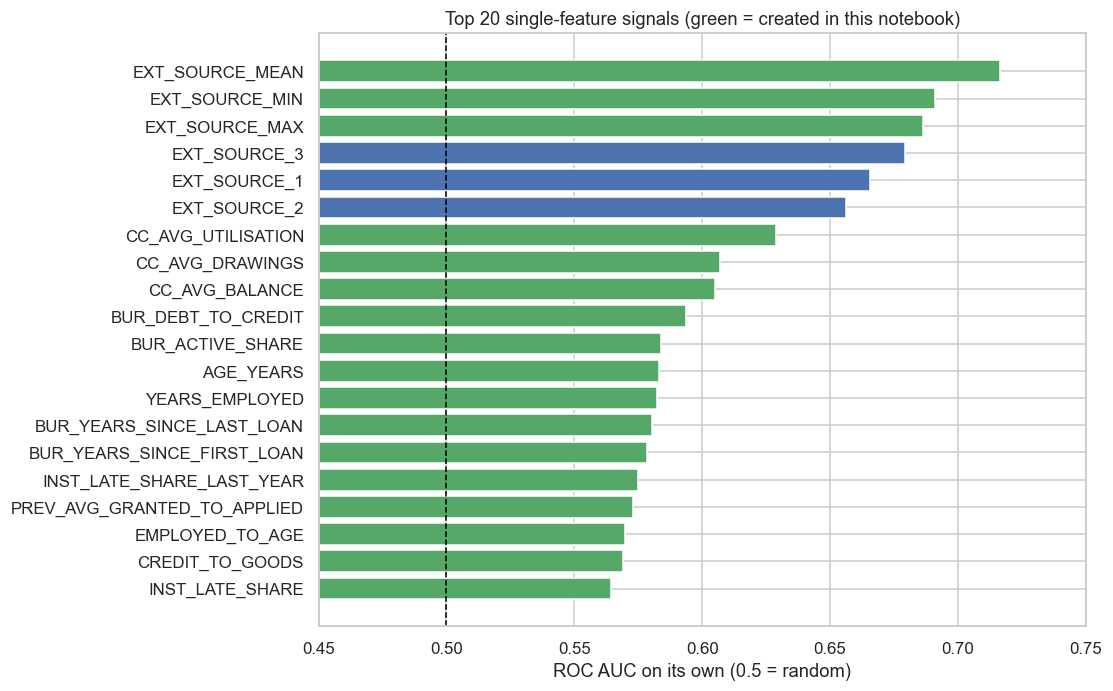

Features created in this notebook among the top 20: 17


,feature,AUC,direction,coverage %,new feature
0,EXT_SOURCE_MEAN,0.717,higher = safer,99.944,True
1,EXT_SOURCE_MIN,0.691,higher = safer,99.944,True
2,EXT_SOURCE_MAX,0.686,higher = safer,99.944,True
3,EXT_SOURCE_3,0.679,higher = safer,80.175,False
4,EXT_SOURCE_1,0.666,higher = safer,43.619,False
5,EXT_SOURCE_2,0.656,higher = safer,99.785,False
6,CC_AVG_UTILISATION,0.629,higher = riskier,27.978,True
7,CC_AVG_DRAWINGS,0.607,higher = riskier,28.261,True
8,CC_AVG_BALANCE,0.605,higher = riskier,28.261,True
9,BUR_DEBT_TO_CREDIT,0.594,higher = riskier,82.974,True


In [16]:
numeric = features.select_dtypes("number").drop(columns=[ID_COL, TARGET_COL])
rows = []
for col in numeric.columns:
    s = numeric[col]
    mask = s.notna()
    if mask.sum() < 1000 or s[mask].nunique() < 2:
        continue
    auc = roc_auc_score(features.loc[mask, TARGET_COL], s[mask])
    rows.append({"feature": col, "AUC": max(auc, 1 - auc),
                 "direction": "higher = riskier" if auc > 0.5 else "higher = safer",
                 "coverage %": mask.mean() * 100,
                 "new feature": col not in raw.columns})
signal = pd.DataFrame(rows).sort_values("AUC", ascending=False).reset_index(drop=True)

top = signal.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top["feature"], top["AUC"], color=np.where(top["new feature"], "#55A868", "#4C72B0"))
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set_xlim(0.45, 0.75)
ax.set_xlabel("ROC AUC on its own (0.5 = random)")
ax.set_title("Top 20 single-feature signals (green = created in this notebook)")
fig.savefig(FIGURES_DIR / "12_feature_signal.png", bbox_inches="tight")
plt.show()

print(f"Features created in this notebook among the top 20: {signal.head(20)['new feature'].sum()}")
signal.head(20)

**Interpretation:**
- **Our engineered features dominate.** The **average external score (`EXT_SOURCE_MEAN`) is the single best feature (AUC ≈ 0.72)**, better than any one external score on its own (0.66–0.68). Combining the three scores paid off.
- **SQL history features made the top 20:** credit-card **utilisation** (≈ 0.63), outside **debt-to-credit** (≈ 0.59), the share of bureau loans still **active**, **recent late payments** (`INST_LATE_SHARE_LAST_YEAR`) and whether past loans were granted above the amount applied for. Past **refusals** (`PREV_REFUSED_SHARE`, AUC ≈ 0.56) just miss the top 20.
- **Loan-structure ratios** such as `CREDIT_TO_GOODS` also appear, confirming the EDA finding that *how* someone borrows matters more than income alone.
- No single feature exceeds about 0.72, so, as EDA predicted, **the model has to combine many signals**. Our target for Step 4 is a combined AUC well above 0.72.

**A caution on coverage:** the credit-card features rank high but exist for only about 28% of applicants. They're very informative *when present*, so the model should use them, but most applicants will be scored mainly on other features.

## 9. Save the feature table and a feature dictionary

We save:
- `data/processed/features.parquet`: the model-ready table. **Parquet** is a compressed, typed format that loads in seconds, versus minutes for CSV.
- `data/processed/features_meta.json`: the income cap and other settings the app needs to clean new applicants the same way.
- `docs/feature_dictionary.csv`: a plain-language description of every column, so teammates, instructors and the AI agent all know what each feature means.

`CODE_GENDER` stays in the table **only for the fairness audit**. It is listed in `PROTECTED_COLS` so the modelling step can exclude it from the model's inputs.

In [17]:
import json

FEATURES_PATH.parent.mkdir(parents=True, exist_ok=True)
features.to_parquet(FEATURES_PATH, index=False)
META_PATH.write_text(json.dumps({"rows": len(features), "columns": features.shape[1], "income_cap": income_cap,
                                 "id_col": ID_COL, "target_col": TARGET_COL, "protected_cols": PROTECTED_COLS}, indent=2))

# Feature dictionary: official descriptions for original columns, our own for engineered ones
official = load_table("HomeCredit_columns_description")
official = official[official["Table"].eq("application_{train|test}.csv")].set_index("Row")["Description"]

engineered = {
    "DAYS_EMPLOYED_ANOM": "1 if DAYS_EMPLOYED was the 365243 placeholder (mostly pensioners)",
    "AGE_YEARS": "Applicant age in years", "YEARS_EMPLOYED": "Years in current job (missing if not employed)",
    "YEARS_SINCE_REGISTRATION": "Years since the applicant changed their registration",
    "YEARS_SINCE_ID_PUBLISH": "Years since the applicant changed the ID document used to apply",
    "YEARS_SINCE_PHONE_CHANGE": "Years since the applicant changed phone number",
    "CREDIT_TO_INCOME": "Loan amount / annual income", "ANNUITY_TO_INCOME": "Loan annuity (regular payment) / income",
    "CREDIT_TO_GOODS": "Loan amount / price of goods (>1 = borrowing extra)", "CREDIT_TERM": "Loan amount / annuity (approx. number of payments)",
    "INCOME_PER_PERSON": "Income / family members", "EXT_SOURCE_MEAN": "Average of available external scores",
    "EXT_SOURCE_MIN": "Lowest external score", "EXT_SOURCE_MAX": "Highest external score",
    "EXT_SOURCE_STD": "Spread of external scores", "EXT_SOURCE_N_MISSING": "Number of missing external scores (0-3)",
    "EXT_SOURCE_1_MISSING": "1 if EXT_SOURCE_1 missing", "EXT_SOURCE_3_MISSING": "1 if EXT_SOURCE_3 missing",
    "AMT_GOODS_PRICE_MISSING": "1 if goods price missing", "EMPLOYED_TO_AGE": "Years employed / age",
    "N_DOCUMENTS": "Number of documents provided", "N_CONTACTS": "Number of contact details provided",
    "BUREAU_ENQUIRIES_YEAR": "Credit bureau enquiries in the year before applying",
    "HAS_BUREAU_HISTORY": "1 if the applicant has any credit bureau record",
    "HAS_PREV_APPLICATION": "1 if the applicant applied to Home Credit before",
}
# Descriptions of SQL features, taken from the AS aliases' meaning
sql_desc = {
    "BUR_N_LOANS": "Number of loans at other lenders", "BUR_N_ACTIVE": "Active loans at other lenders",
    "BUR_ACTIVE_SHARE": "Share of bureau loans still active", "BUR_N_BAD_DEBT": "Bureau loans marked bad debt",
    "BUR_N_CREDIT_TYPES": "Distinct credit types at other lenders", "BUR_YEARS_SINCE_LAST_LOAN": "Years since most recent bureau loan",
    "BUR_YEARS_SINCE_FIRST_LOAN": "Years since oldest bureau loan", "BUR_TOTAL_CREDIT": "Total credit at other lenders",
    "BUR_TOTAL_DEBT": "Total current debt at other lenders", "BUR_DEBT_TO_CREDIT": "Bureau debt / bureau credit (utilisation)",
    "BUR_TOTAL_OVERDUE": "Total overdue amount at other lenders", "BUR_MAX_DAYS_OVERDUE": "Max days currently overdue at other lenders",
    "BUR_N_OVERDUE_NOW": "Bureau loans currently overdue", "BUR_N_PROLONGED": "Times bureau loans were prolonged",
    "BB_N_MONTHS": "Months of bureau balance history", "BB_LATE_MONTH_SHARE": "Share of bureau months past due",
    "BB_N_SEVERE_LATE_MONTHS": "Bureau months 60+ days past due",
    "PREV_N_APPS": "Previous Home Credit applications", "PREV_N_APPROVED": "Previous applications approved",
    "PREV_N_REFUSED": "Previous applications refused", "PREV_REFUSED_SHARE": "Share of previous applications refused",
    "PREV_CANCELED_SHARE": "Share of previous applications canceled", "PREV_AVG_AMT_APPLIED": "Average amount applied for previously",
    "PREV_AVG_GRANTED_TO_APPLIED": "Average granted / applied amount on previous applications", "PREV_AVG_TERM": "Average term of previous loans",
    "PREV_YEARS_SINCE_LAST_DECISION": "Years since last previous decision", "PREV_N_REFUSED_LAST_YEAR": "Refusals in the last year",
    "INST_N_PAYMENTS": "Past installments due", "INST_LATE_SHARE": "Share of installments paid late or not paid",
    "INST_AVG_DAYS_LATE": "Average days late per installment", "INST_MAX_DAYS_LATE": "Most days late on one installment",
    "INST_UNDERPAID_SHARE": "Share of installments underpaid", "INST_TOTAL_UNDERPAID": "Total amount underpaid",
    "INST_LATE_SHARE_LAST_YEAR": "Share of installments late in the last year",
    "POS_N_LOANS": "Previous POS/cash loans", "POS_N_MONTHS": "Months of POS/cash history",
    "POS_LATE_MONTH_SHARE": "Share of POS/cash months past due", "POS_MAX_DPD": "Max days past due on POS/cash loans",
    "POS_N_COMPLETED": "Completed POS/cash loans", "CC_N_CARDS": "Previous Home Credit cards", "CC_N_MONTHS": "Months of card history",
    "CC_AVG_BALANCE": "Average card balance", "CC_AVG_UTILISATION": "Average card balance / limit",
    "CC_AVG_DRAWINGS": "Average monthly card drawings", "CC_BELOW_MIN_PAYMENT_SHARE": "Share of months paying below the minimum",
    "CC_LATE_MONTH_SHARE": "Share of card months past due", "CC_MAX_DPD": "Max days past due on cards",
}
source_of = lambda c: next((name for p, name in prefixes.items() if c.startswith(p)), "Engineered" if c in engineered else "Application")
dictionary = pd.DataFrame({
    "feature": features.columns,
    "source": [source_of(c) for c in features.columns],
    "description": [engineered.get(c) or sql_desc.get(c) or official.get(c, "") for c in features.columns],
    "use_in_model": [c not in (ID_COL, TARGET_COL, *PROTECTED_COLS) for c in features.columns],
})
dictionary.to_csv(ROOT / "docs" / "feature_dictionary.csv", index=False)

print(f"Saved {FEATURES_PATH.relative_to(ROOT)} ({FEATURES_PATH.stat().st_size / 1e6:.0f} MB)")
print(f"Saved docs/feature_dictionary.csv ({len(dictionary)} features, {dictionary['description'].eq('').sum()} without description)")
dictionary["source"].value_counts().rename("number of features").to_frame()

Saved data\processed\features.parquet (47 MB)
Saved docs/feature_dictionary.csv (161 features, 0 without description)


,number of features
source,
Application,89
Engineered,25
Credit bureau,14
Previous applications,10
Credit cards,8
Installment payments,7
POS / cash loans,5
Bureau monthly balance,3


## 10. Summary and next steps

**What we built:**
- A **cleaned** application table, with every fix traced back to an EDA finding.
- **25 engineered features** encoding lending logic (ratios, combined external scores, missingness flags).
- A **SQLite database** of 58 million history rows and **47 SQL features** summarising each applicant's past behaviour.
- **One validated table:** 307,511 applicants × 161 columns, saved as Parquet, plus a feature dictionary.

**What we learned:**
- Combining the three external scores (`EXT_SOURCE_MEAN`, AUC ≈ 0.72) beats any single score.
- Past behaviour from SQL (card utilisation, debt-to-credit, recent late payments, refusals) adds real signal.
- No single feature is enough, which supports a model that combines them all.

**Next: Step 4, modelling** (`03_modelling.ipynb`):
1. Stratified train/test split (keep 8% defaults in both).
2. **Baseline:** logistic regression with imputation and scaling.
3. **Main model:** LightGBM with class weights.
4. Evaluate with ROC AUC, precision, recall and a confusion matrix, and choose the approval cutoff by expected profit.
5. Save the model for SHAP explanations and the Streamlit app.

**To rebuild everything from scratch** (e.g. on a teammate's laptop), run this notebook, or from the project root:

```bash
cd src && python -m secondlook.features
```